# Wumpus World, solution 2: a learned policy (Learning Classifier System)

**The task** is the same as in solution 1: grab the gold and climb out from (1,1).

| Event | Reward |
|---|---|
| climb out with the gold | +1000 |
| die (pit or Wumpus) | −1000 |
| every action | −1 |
| shoot the arrow | −10 |

**The idea of this solution.** Nobody writes the rules, and the agent doesn't know the map. It starts with **no rules at all** and learns them by trial and error, from rewards that are *sparse* (almost every step gives just −1) and *delayed* (the +1000 arrives only at the very end).

The learner is a **Learning Classifier System (LCS)**:

| Component | Job | Here |
|---|---|---|
| **Performance** | match the rules against the messages, pick one, act | auction: `bid = c · specificity · strength` |
| **Reinforcement** | give each rule its share of the reward | Holland's **bucket brigade** |
| **Discovery** | create new rules | **covering**: create a rule when one is missing |

In [1]:
import random
from dataclasses import dataclass
import matplotlib.pyplot as plt

In [2]:
DIRS = ["east", "north", "west", "south"]          # turn_l = next one, turn_r = previous one
STEP = {"east": (1, 0), "north": (0, 1), "west": (-1, 0), "south": (0, -1)}
ACTIONS = ["fwd", "turn_l", "turn_r", "grab", "shoot", "climb"]


class Cave:
    def __init__(self, wumpus=(1, 3), gold=(2, 3), pits=((3, 1), (3, 3), (4, 4)), size=4):
        self.size, self.wumpus0, self.gold0, self.pits = size, wumpus, gold, set(pits)
        self.reset()

    def reset(self):
        self.pos, self.facing = (1, 1), "east"
        self.wumpus, self.gold = self.wumpus0, self.gold0
        self.has_gold, self.arrow, self.done = False, True, False
        self.bump = self.scream = False
        return self.sensors()

    def neighbours(self, square):
        x, y = square
        return {(x + dx, y + dy) for dx, dy in STEP.values()
                if 1 <= x + dx <= self.size and 1 <= y + dy <= self.size}

    def sensors(self):
        s = set()
        if self.wumpus and self.wumpus in self.neighbours(self.pos) | {self.pos}: s.add("stench")
        if self.pits & self.neighbours(self.pos): s.add("breeze")
        if self.gold == self.pos: s.add("glitter")
        if self.bump: s.add("bump")
        if self.scream: s.add("scream")
        if self.pos == (1, 1): s.add("at_start")
        return s

    def step(self, action):
        self.bump = self.scream = False
        reward = -1                                         # every action costs 1
        if action == "fwd":
            dx, dy = STEP[self.facing]
            new = (self.pos[0] + dx, self.pos[1] + dy)
            if 1 <= new[0] <= self.size and 1 <= new[1] <= self.size:
                self.pos = new
                if new in self.pits or new == self.wumpus:
                    self.done, reward = True, -1000         # pit or Wumpus
            else:
                self.bump = True                            # wall
        elif action == "turn_l":
            self.facing = DIRS[(DIRS.index(self.facing) + 1) % 4]
        elif action == "turn_r":
            self.facing = DIRS[(DIRS.index(self.facing) - 1) % 4]
        elif action == "grab" and self.gold == self.pos:
            self.has_gold, self.gold = True, None
        elif action == "shoot" and self.arrow:
            self.arrow, reward = False, -10
            x, y = self.pos
            dx, dy = STEP[self.facing]
            while 1 <= x <= self.size and 1 <= y <= self.size:
                if (x, y) == self.wumpus:
                    self.wumpus, self.scream = None, True
                    break
                x, y = x + dx, y + dy
        elif action == "climb" and self.pos == (1, 1):
            self.done = True
            if self.has_gold:
                reward = 1000 - 1                           # +1000, minus the action's cost
        return self.sensors(), reward

In [3]:
class Memory:
    def reset(self):
        self.x, self.y, self.facing, self.has_gold = 1, 1, "east", False

    def messages(self):
        return {f"x{self.x}", f"y{self.y}", f"facing_{self.facing}",
                "has_gold" if self.has_gold else "no_gold"}

    def update(self, action, sensors_before, sensors_after):
        if action == "fwd" and "bump" not in sensors_after:
            dx, dy = STEP[self.facing]
            self.x, self.y = self.x + dx, self.y + dy
        elif action == "turn_l":
            self.facing = DIRS[(DIRS.index(self.facing) + 1) % 4]
        elif action == "turn_r":
            self.facing = DIRS[(DIRS.index(self.facing) - 1) % 4]
        elif action == "grab" and "glitter" in sensors_before:
            self.has_gold = True


def show(msgs):
    # Messages in a readable order: memory first, then sensors.
    mem = [m for m in msgs if m[0] in "xyf" or m.endswith("gold")]
    return "{" + ", ".join(sorted(mem) + sorted(set(msgs) - set(mem))) + "}"

In [4]:
def draw(cave, path, title, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(4.2, 4.2))
    for x in range(1, 5):
        for y in range(1, 5):
            ax.add_patch(plt.Rectangle((x - .5, y - .5), 1, 1, fill=False, ec="#999"))
    for (x, y) in cave.pits:
        ax.add_patch(plt.Circle((x, y), .28, color="black"))
    ax.add_patch(plt.Circle(cave.wumpus0, .28, color="#1f6b2e"))
    ax.text(*cave.wumpus0, "W", color="white", ha="center", va="center", fontweight="bold")
    gx, gy = cave.gold0
    ax.add_patch(plt.Polygon([(gx, gy + .28), (gx + .28, gy), (gx, gy - .28), (gx - .28, gy)], color="#1c5f86"))
    xs, ys = zip(*path)
    ax.plot(xs, ys, "-o", color="#b4441e", lw=3, ms=7, alpha=.85)
    ax.set_xlim(.5, 4.5); ax.set_ylim(.5, 4.5); ax.set_aspect("equal")
    ax.set_xticks(range(1, 5)); ax.set_yticks(range(1, 5)); ax.set_title(title)
    return ax

## Classifiers

A classifier is a rule `condition → action`, as in solution 1, plus a **strength**: how much the system trusts it, learned from the rewards.

- It **matches** when its condition is a subset of the current messages.
- Its **specificity** is the fraction of the current messages that its condition requires (1 = it requires all of them).
- Its **bid** in the auction is `c · specificity · strength`. `c` is a small constant, the share of its strength that a rule is willing to bet.

In [5]:
@dataclass(eq=False)              # eq=False: two rules are equal only if they are the same object
class Classifier:
    condition: frozenset
    action: str
    strength: float
    uses: int = 0

    def matches(self, msgs):
        return self.condition <= msgs

    def specificity(self, msgs):
        return len(self.condition) / len(msgs)

    def bid(self, msgs, c):
        return c * self.specificity(msgs) * self.strength

    def __str__(self):
        return f"{show(self.condition):<58} -> {self.action:<7} strength {self.strength:7.1f}"

## The three components

### Performance: the auction

All the rules that match the current messages form the **match set**. Each one bids, and the **highest bid wins**: its action is executed.
To keep learning, the system sometimes lets a random matching rule win instead (**exploration**). The probability of this starts at 10% and falls to 0 by the end of training: first explore, then exploit what has been learned.

### Discovery: covering

When the match set has no rule for some action, a new rule is created with the current messages as its condition and that action. The system therefore starts empty and grows rules as it meets new situations.
A new rule starts with an **optimistic** strength of 1000. An untried action then looks better than the ones that have already disappointed, so the agent keeps trying new things. Experiment 1 shows what happens without this.

### Reinforcement: the bucket brigade

The reward comes only at the end, but many rules contributed to it: they *set the stage* for the rules that came after them. The bucket brigade passes the reward back along the chain, like a line of people passing buckets of water:

1. **The winner pays its bid to the previous winner.** The rule that set the stage is paid by the rule that profited from it.
2. **The winner receives the reward** of its action from the environment.

A rule that leads to good rules gets paid more than it pays and grows stronger; a rule that leads to deaths or dead ends gets weaker. After enough episodes the final +999 has flowed back, a step at a time, all the way to the first rule of the route.

In [6]:
class LCS:
    def __init__(self, c=0.2, initial_strength=1000.0, explore=0.1, seed=0):
        self.c = c                                  # bid coefficient
        self.initial_strength = initial_strength    # optimistic start for new rules
        self.explore = explore                      # current exploration probability
        self.rng = random.Random(seed)
        self.rules = []                             # the population: starts empty
        self.covering = True

    # ---- discovery: covering ---------------------------------------------
    def match_set(self, msgs):
        match = [r for r in self.rules if r.matches(msgs)]
        present = {r.action for r in match}
        for action in ACTIONS:
            if self.covering and action not in present:
                new = Classifier(msgs, action, self.initial_strength)
                self.rules.append(new)
                match.append(new)
        return match

    # ---- performance: the auction ------------------------------------------
    def auction(self, match, msgs, learning):
        if learning and self.rng.random() < self.explore:
            return self.rng.choice(match)                       # explore
        best = max(r.bid(msgs, self.c) for r in match)
        return self.rng.choice([r for r in match if r.bid(msgs, self.c) == best])

    # ---- one episode, with the bucket brigade ----------------------------------
    def episode(self, cave, learning=True, max_steps=60, trace=False):
        memory = Memory(); memory.reset()
        sensors = cave.reset()
        previous, score, path = None, 0, [cave.pos]
        for t in range(1, max_steps + 1):
            msgs = frozenset(sensors | memory.messages())
            match = self.match_set(msgs)
            winner = self.auction(match, msgs, learning)
            winner.uses += 1
            if trace:
                print(f"{t:>2}  {winner}")

            if learning:                                        # bucket brigade, part 1
                bid = winner.bid(msgs, self.c)
                winner.strength -= bid                          # the winner pays its bid...
                if previous is not None:
                    previous.strength += bid                    # ...to the rule that set the stage

            new_sensors, reward = cave.step(winner.action)
            if learning:                                        # bucket brigade, part 2
                winner.strength += reward                       # the environment pays the winner

            memory.update(winner.action, sensors, new_sensors)
            sensors, score = new_sensors, score + reward
            path.append(cave.pos)
            previous = winner
            if cave.done:
                break
        return score, path

    def train(self, cave, episodes=2000, explore_start=0.1):
        scores = []
        for e in range(episodes):
            self.explore = explore_start * (1 - e / episodes)  # exploration fades to 0
            scores.append(self.episode(cave)[0])
        return scores

## Training

In [7]:
lcs = LCS(seed=0)
scores = lcs.train(Cave(), episodes=2000)

wins = [s > 0 for s in scores]
print(f"first time out with the gold: episode {wins.index(True) + 1}")
print(f"wins in the last 200 episodes: {sum(wins[-200:])}/200")
print(f"rules created by covering: {len(lcs.rules)}")

first time out with the gold: episode 69
wins in the last 200 episodes: 200/200
rules created by covering: 702


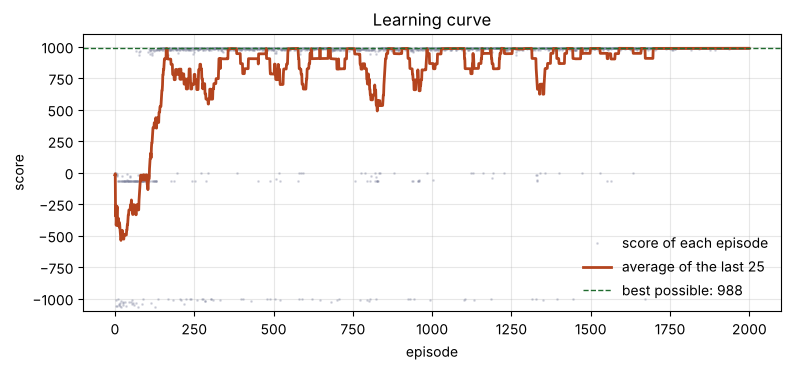

In [8]:
def moving_average(xs, n=25):
    return [sum(xs[max(0, i - n + 1):i + 1]) / len(xs[max(0, i - n + 1):i + 1]) for i in range(len(xs))]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(scores, ".", ms=2, alpha=.25, color="#7a7f9a", label="score of each episode")
ax.plot(moving_average(scores), color="#b4441e", lw=2, label="average of the last 25")
ax.axhline(988, ls="--", lw=1, color="#1f6b2e", label="best possible: 988")
ax.set_xlabel("episode"); ax.set_ylabel("score"); ax.set_ylim(-1100, 1100)
ax.legend(loc="lower right", frameon=False); ax.grid(alpha=.3); ax.set_title("Learning curve")
plt.show()

At first the agent often dies (−1000) or wanders without the gold (below 0). Once it has climbed out with the gold a few times, the bucket brigade passes the reward back along the chain of rules, and the scores climb. The late dips are exploration, which fades to zero by the end.

## The learned policy

Now the agent plays without exploring and without learning: at every step the highest bid wins.

 1  {facing_east, no_gold, x1, y1, at_start}                   -> turn_l  strength  4843.1
 2  {facing_north, no_gold, x1, y1, at_start}                  -> fwd     strength  4884.3
 3  {facing_north, no_gold, x1, y2, stench}                    -> turn_r  strength  4913.9
 4  {facing_east, no_gold, x1, y2, stench}                     -> fwd     strength  4933.2
 5  {facing_east, no_gold, x2, y2}                             -> turn_l  strength  4945.3
 6  {facing_north, no_gold, x2, y2}                            -> fwd     strength  4953.4
 7  {facing_north, no_gold, x2, y3, breeze, glitter}           -> grab    strength  5786.1
 8  {facing_north, has_gold, x2, y3, breeze, stench}           -> turn_l  strength  4964.9
 9  {facing_west, has_gold, x2, y3, breeze, stench}            -> turn_l  strength  4970.0
10  {facing_south, has_gold, x2, y3, breeze}                   -> fwd     strength  5970.0
11  {facing_south, has_gold, x2, y2}                           -> fwd     strength  4980.0

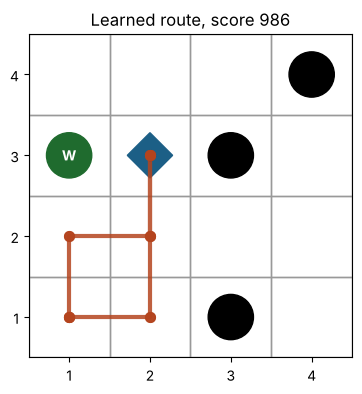

In [9]:
score, path = lcs.episode(Cave(), learning=False, trace=True)
print(f"\nScore: {score}")
draw(Cave(), path, f"Learned route, score {score}")
plt.show()

The agent learned to go out through (1,2) and come back through (2,1): 14 actions and **986** points, two actions more than the shortest route that solution 1 planned by hand.

In [11]:
for r in lcs.rules:
    r.uses = 0
lcs.episode(Cave(), learning=False)                 # count which rules win now

before = len(lcs.rules)
lcs.rules = [r for r in lcs.rules if r.uses > 0]    # remove the lazy ones
lcs.covering = False                                # and create no new ones
print(f"rules: {before} -> {len(lcs.rules)}\n")
for r in lcs.rules:
    print(r)
print(f"\nscore with only these rules: {lcs.episode(Cave(), learning=False)[0]}")

rules: 702 -> 14

{facing_east, no_gold, x1, y1, at_start}                   -> turn_l  strength  4843.1
{facing_north, no_gold, x1, y1, at_start}                  -> fwd     strength  4884.3
{facing_north, no_gold, x2, y2}                            -> fwd     strength  4953.4
{facing_east, no_gold, x2, y2}                             -> turn_l  strength  4945.3
{facing_north, no_gold, x1, y2, stench}                    -> turn_r  strength  4913.9
{facing_east, no_gold, x1, y2, stench}                     -> fwd     strength  4933.2
{facing_west, has_gold, x2, y3, breeze, stench}            -> turn_l  strength  4970.0
{facing_north, has_gold, x2, y3, breeze, stench}           -> turn_l  strength  4964.9
{facing_south, has_gold, x2, y2}                           -> fwd     strength  4980.0
{facing_south, has_gold, x2, y1, breeze}                   -> turn_r  strength  4985.0
{facing_south, has_gold, x2, y3, breeze}                   -> fwd     strength  5970.0
{facing_west, has_gold, x

## Experiments

### 1. Is the result always the same?

Learning involves chance: the random exploratory moves. Train eight systems that differ only in the random seed.

In [12]:
results = []
for seed in range(8):
    run = LCS(seed=seed)
    s = run.train(Cave(), 2000)
    results.append(run.episode(Cave(), learning=False)[0])
print("final scores:", results)
print(f"actions used: {[1000 - s for s in results]}  (the minimum is 12)")

final scores: [986, 987, 983, 988, 988, 985, 986, 986]
actions used: [14, 13, 17, 12, 12, 15, 14, 14]  (the minimum is 12)


Every system learns to get the gold and come back, but not always by the shortest route. This is a known limit of the bucket brigade: a rule is paid the bid of the rule that **actually** fires next, exploratory moves included. Once a route works, the system keeps reinforcing it, and a slightly shorter route explored only a few times may never collect enough strength to win the auction. The bucket brigade finds a **good** policy; it does not guarantee the **best** one.

### 2. A different cave

Move the gold to (4,2), the change that broke the hand-written rules of solution 1, and train a new system.

Score in the changed cave: 985


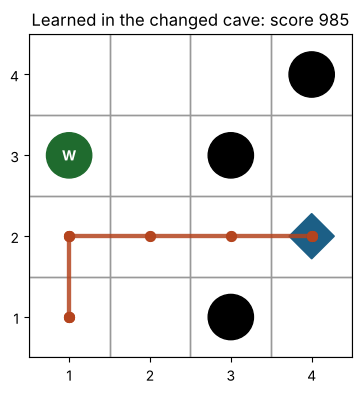

In [14]:
other = Cave(gold=(4, 2))
lcs2 = LCS(seed=0)
lcs2.train(other, 2000)
score2, path2 = lcs2.episode(other, learning=False)
print(f"Score in the changed cave: {score2}")
draw(other, path2, f"Learned in the changed cave: score {score2}")
plt.show()